<a href="https://colab.research.google.com/github/starfgrhtjyjyku/financial-risk-assessment/blob/main/Financial_Risk_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files

uploaded = files.upload()

Saving german_credit_data_updated.csv to german_credit_data_updated.csv


In [4]:
#Reading with dataset

df = pd.read_csv('german_credit_data_updated.csv')
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,2,49,male,1,own,little,NaN,2096,12,education,1
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,4,53,male,2,free,little,little,4870,24,car,2


**Understanding Data Set**

In [5]:
df.shape

(954, 11)

In [6]:
df.columns

Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose',
       'Credit Risk'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 954 entries, 0 to 953
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        954 non-null    int64 
 1   Age               954 non-null    int64 
 2   Sex               954 non-null    object
 3   Job               954 non-null    int64 
 4   Housing           954 non-null    object
 5   Saving accounts   779 non-null    object
 6   Checking account  576 non-null    object
 7   Credit amount     954 non-null    int64 
 8   Duration          954 non-null    int64 
 9   Purpose           954 non-null    object
 10  Credit Risk       954 non-null    int64 
dtypes: int64(6), object(5)
memory usage: 82.1+ KB


In [8]:
df.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration,Credit Risk
count,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000
mean,476.500000,35.501048,1.909853,3279.112159,20.780922,1.302935
std,275.540378,11.379668,0.649681,2853.315158,12.046483,0.459768
min,0.000000,19.000000,0.000000,250.000000,4.000000,1.000000
25%,238.250000,27.000000,2.000000,1360.250000,12.000000,1.000000
50%,476.500000,33.000000,2.000000,2302.500000,18.000000,1.000000
75%,714.750000,42.000000,2.000000,3975.250000,24.000000,2.000000
max,953.000000,75.000000,3.000000,18424.000000,72.000000,2.000000


In [9]:
df.sample(5)

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
374,374,60,female,3,free,moderate,moderate,14782,60,vacation/others,2
660,660,23,male,2,rent,little,rich,1297,12,radio/TV,1
176,176,42,male,2,own,little,little,2577,12,furniture/equipment,1
917,917,68,male,3,own,little,little,14896,6,car,2
266,266,36,male,2,own,NaN,NaN,6304,36,business,1


**Missing Value Analysis**

In [15]:
df.isnull().sum()

,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,175
Checking account,378
Credit amount,0
Duration,0
Purpose,0


In [16]:
missing = pd.DataFrame(df.isnull().sum(),columns=['Missing Values'])
missing

,Missing Values
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,175
Checking account,378
Credit amount,0
Duration,0
Purpose,0


**Understanding Target Variable**

In [17]:
#Distribution
df['Credit Risk'].value_counts()

,count
Credit Risk,
1,665
2,289


In [18]:
df['Credit Risk'].value_counts(normalize=True)*100

,proportion
Credit Risk,
1,69.706499
2,30.293501


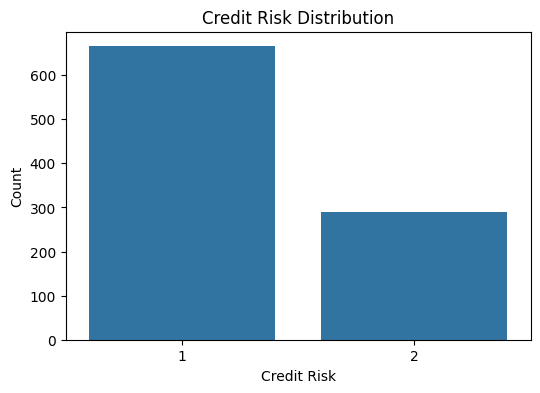

In [14]:
plt.figure(figsize=(6,4))

sns.countplot(x='Credit Risk', data=df)

plt.title('Credit Risk Distribution')
plt.xlabel('Credit Risk')
plt.ylabel('Count')

plt.show()

In [19]:
#Missing Values Analysis

missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': round(df.isnull().mean()*100,2)
})

missing.sort_values('Missing Values', ascending=False)

,Missing Values,Percentage
Checking account,378,39.62
Saving accounts,175,18.34
Unnamed: 0,0,0.00
Sex,0,0.00
Age,0,0.00
Housing,0,0.00
Job,0,0.00
Credit amount,0,0.00
Duration,0,0.00
Purpose,0,0.00


In [21]:
df['Unnamed: 0'].head()
#Unnamed:0 is simply an index, contains no predictive information. Thus, dropping it

df = df.drop('Unnamed: 0', axis=1)

In [22]:
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,49,male,1,own,little,NaN,2096,12,education,1
3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,53,male,2,free,little,little,4870,24,car,2


**Basic EDA**

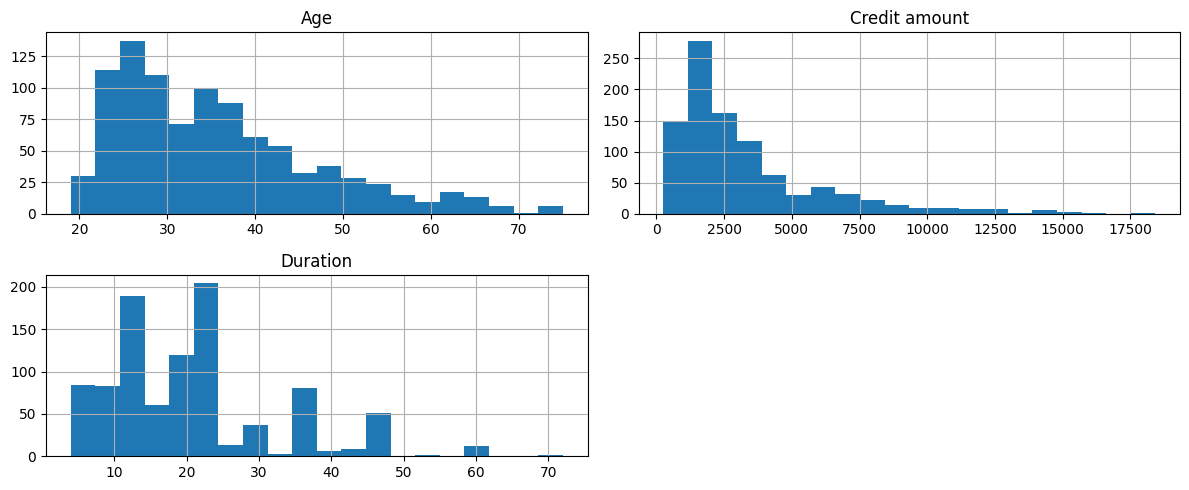

In [24]:
num_cols = ['Age','Credit amount','Duration']
df[num_cols].hist(figsize=(12,5),bins= 20)
plt.tight_layout()
plt.show()

**Target Variables vs Numeric Variables**

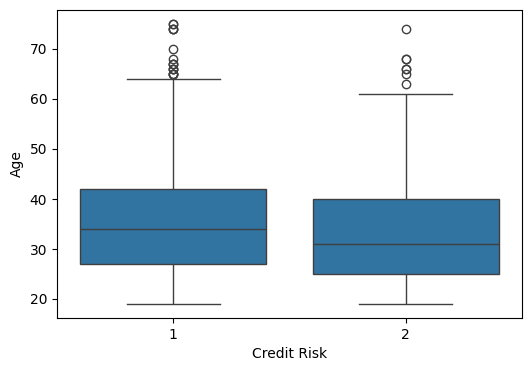

In [25]:
# Age vs Credit Risk
plt.figure(figsize=(6,4))

sns.boxplot(x= 'Credit Risk', y= 'Age', data=df)
plt.show()

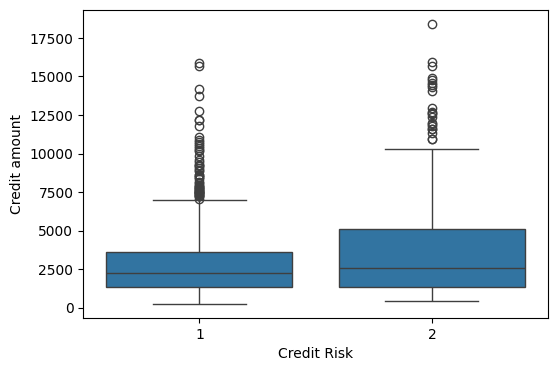

In [26]:
#Credit Amount vs Credit Risk

plt.figure(figsize=(6,4))

sns.boxplot(x= 'Credit Risk', y= 'Credit amount', data=df)
plt.show()